# Würfelspiel

Im Würfelspiel Ratte muss man gleichzeitig mit 9 Würfel würfeln und Punkte erzielen. Die größte Punkte-bringende Konstellation an Würfeln ist die Ratte, eine Straße von 1-6.

- Erstellen Sie $N = 10^4$ Würfelergebnisse mit `numpy.random.choice(<Liste möglicher Werte>, size=(<#Werte>, <#Würfel>))` 
- Bestimmen Sie die Wahrscheinlichkeit eine Ratte zu Würfel mit 9, 8, 7 und 6 Würfeln.

Tipps:
- `numpy.unique()` gibt ein Array mit allen Einzigartigen Elementen zurück
- `len()` gibt die Länge eines Arrays zurück




In [69]:
import numpy as np
import matplotlib.pyplot as plt

n = 10**4
data = np.random.choice(np.arange(1,7), size=(n, 9))
data8 = np.random.choice(np.arange(1,7), size=(n, 8))
data7 = np.random.choice(np.arange(1,7), size=(n, 7))
data6 = np.random.choice(np.arange(1,7), size=(n, 6))

ratte = 0
ratte8 = 0
ratte7 = 0
ratte6 = 0

for i in range(n):
    if len(np.unique(data[i])) == 6:
        ratte += 1
    if len(np.unique(data8[i])) == 6:
        ratte8 += 1
    if len(np.unique(data7[i])) == 6:
        ratte7 += 1
    if len(np.unique(data6[i])) == 6:
        ratte6 += 1

P = ratte/n
P8 = ratte8/n
P7 = ratte7/n
P6 = ratte6/n

print(f"Ratte9: {round(P*100, 2)} %")
print(f"Ratte8: {round(P8*100, 2)} %")
print(f"Ratte7: {round(P7*100, 2)} %")
print(f"Ratte6: {round(P6*100, 2)} %")

Ratte9: 18.93 %
Ratte8: 11.2 %
Ratte7: 5.34 %
Ratte6: 1.59 %


# Coupon Collectors Problem

Ein Sammelkartenspiel besteht aus insgesamt r unterschiedlichen Karten.

Beim Kauf eines Kartenpacks erhält man k unterschiedliche Karten.
Jede gezogene Karte ist unabhängig und mit gleicher Wahrscheinlichkeit eine der r Karten.

Ein Spieler kauft so lange Kartenpacks, bis er alle r Karten mindestens einmal besitzt.

- Erstellen Sie $N=10^4$ zufällige Kartenpacks-Ziehungen mit
  - r = 50 verschiedene Karten
  - k = 5 Karten pro Pack
- Bestimmen Sie die durchschnittliche Anzahl von gekauften Kartenpacks.
- Plotten Sie ein Histogramm der benötigten Packs.
- Bestimmen Sie die Wahrscheinlichkeit, dass mehr als 30 Packs benötigt werden
- Zusatz: Bestimmen Sie die durchschnittliche Anzahl von gekauften Kartenpacks, wenn in einem Kartenpacks die gleichen Karten enthalten sein können. 

Durchschnittliche durchläufe: 43.005
Größer 30: 90.7 %


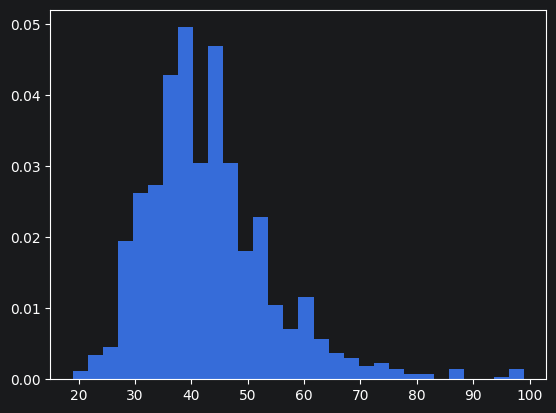

In [103]:
import numpy as np
import matplotlib.pyplot as plt

n = 10**4
r = 50
k = 5

karten = np.arange(1, r+1)
gesamtDurchlaufe = []
alleGezogeneKarten = []
gesamt = 0

for i in range(1000):
    gezogeneKarten = []
    durchlaufe = 0
    while True:
        durchlaufe += 1
        data = np.random.choice(np.arange(1, r+1), size=5, replace=False)
        gezogeneKarten.extend(data)
        #print(gezogeneKarten)

        if(len(np.unique(gezogeneKarten)) == 50):
            gesamt += durchlaufe
            gesamtDurchlaufe.append(durchlaufe)
            alleGezogeneKarten.extend(gezogeneKarten)
            break

print(f"Durchschnittliche durchläufe: {gesamt/1000}")

plt.hist(gesamtDurchlaufe, density=True, bins=30)

groesser30 = 0
for durchlauf in gesamtDurchlaufe:
    if(durchlauf > 30):
        groesser30 += 1

print(f"Größer 30: {(groesser30/1000)*100} %")


# Bauteillager

In einem Bauteillager befinden sich drei unterschiedliche Widerstandswerte. Zu 55% ist das Lager mit 1k Ohm, zu 30% mit 10k Ohm und der Rest mit 100k Ohm Widerstände gefüllt.
Für eine Qualitätskontrolle wird zunächst ein Widerstand zufällig aus dem Lager ausgewählt.

- Erstellen Sie $N=10^4$ zufällige Ziehungen mit `numpy.random.choice(<values>, size=<#Werte>, p=<Wahrscheinlichkeiten>)`.
- Wie groß ist die Wahrscheinlichkeit einen Widerstand größer als 5k Ohm auszuwählen?
- Bestimmen sie den mittleren Widerstandswert
- Plotten Sie ein Häufigkeit der Widerstandswerte in einem Balkendiagramm oder Histogramm.

In [122]:
import numpy as np
import matplotlib.pyplot as plt

n = 10**4

k1_Ohm = [1] * 55
k10_Ohm = [10] * 30
k100_Ohm = [100] * 15
lager = []

lager.extend(k1_Ohm)
lager.extend(k10_Ohm)
lager.extend(k100_Ohm)

data = np.random.choice(lager, size=(n, 1))
g5 = 0

for r in data:
    if r > 5:
        g5 += 1

print(f"Größer 5k Ohm: {(g5/n)*100} %")
print(f"Mittlerer Widerstandswert: {sum(data)/n} kOhm")

#plt.hist(data, density=True, bins=30)


Größer 5k Ohm: 45.43 %
Mittlerer Widerstandswert: [18.1477] kOhm


# Monte-Carlo Bestimmung von $\pi$
Gegeben ist ein Quadrat mit Seitenlänge 2 und ein darin einbeschriebener Einheitskreis.

Schätzen Sie $\pi$ mithilfe einer Monte-Carlo-Simulation.


- Erzeugen Sie $N = 10^4$ gleichverteilte Zufallspunkte im Bereich $[-1,1] [-1,1]$ mit `numpy.random.uniform()`.
- Bestimmen Sie den Anteil der Punkte innerhalb des Kreises und damit näherungsweise die Zahl $\pi$.
- Visualisieren Sie die Punkte (Treffer/Nicht-Treffer).
- Untersuchen Sie den Fehler für $N = 10^2$ bis $10^6$ mit `np.pi`.

Kreis: 0.7854
Pi: 3.1416


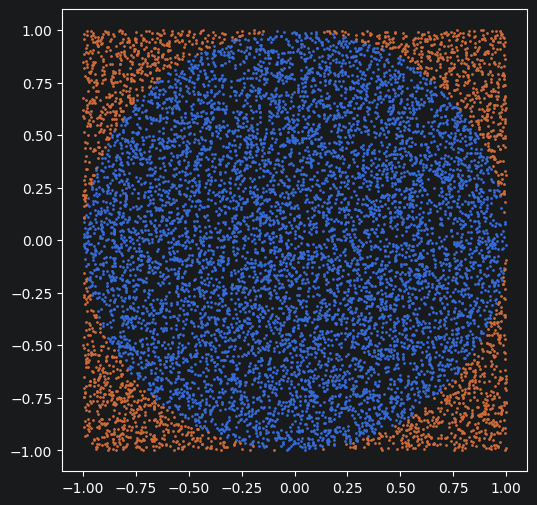

In [140]:
import numpy as np
import matplotlib.pyplot as plt

n = 10**4

x = np.random.uniform(-1, 1, size=n)
y = np.random.uniform(-1, 1, size=n)
imKreis = 0

for i in range(n):
    # x^2 + y^2 = r^1 -> Kreisgleichung
    if x[i]**2 + y[i]**2 < 1:
        imKreis += 1

inside_circle = x**2 + y**2 < 1

p_imKreis = imKreis/n

print(f"Kreis: {imKreis/n}")
pi = 4*p_imKreis/1
print(f"Pi: {pi}")

fig = plt.figure(figsize=(6, 6))
plt.scatter(x[inside_circle], y[inside_circle], s=1)
plt.scatter(x[~inside_circle], y[~inside_circle], s=1)
plt.show()



# Käfer auf der Uhr
Ein Käfer sitzt auf der Zahl 12 eines Ziffernblattes. Er bewegt sich mit jedem Schritt mit gleicher Wahrscheinlichkeit nach rechts oder nach links (Beispiel nach Schritt 1 ist der Käfer entweder auf der 11 oder auf der 1). Nachdem er jede Zahl von 1 bis 11 mindestens einmal besucht hat stoppt er. 

- Wie groß ist Wahrscheinlichkeit, dass der Käfer auf der Zahl 6 stoppt (d.h. die 6 ist die letzte Zahl auf der er landet)?
- Wie ändert sich die Wahrscheinlichkeit, wenn die Chance 45% ist gegen den Uhrzeigersinn und 55% mit dem Uhrzeigersinn zu gehen?

In [73]:
import numpy as np
import matplotlib.pyplot as plt

# Monte-Carlo-Integration einer Kurve
Bestimmen Sie die Fläche unter der Kurve

$$f(x) = e^{-x^2}$$

im Bereich

$$x \in [-2,2]$$

- Plotten sie die Funktion im Bereich [-2, 2]
- Verwenden Sie eine Monte-Carlo-Integration.
  - Zur Generierung der Zufallspunkte verwenden Sie `numpy.random.uniform` mit dem angegebenen Definitionsbereich.
- Visualisieren Sie Punkte unter und über der Kurve.
- Vergleichen Sie mit `numpy.trapz()`.

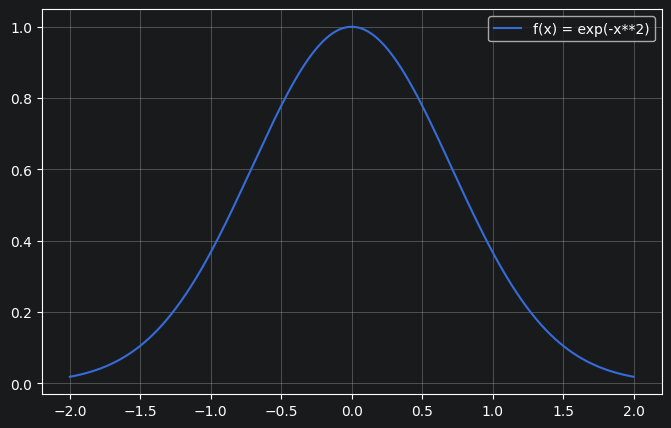

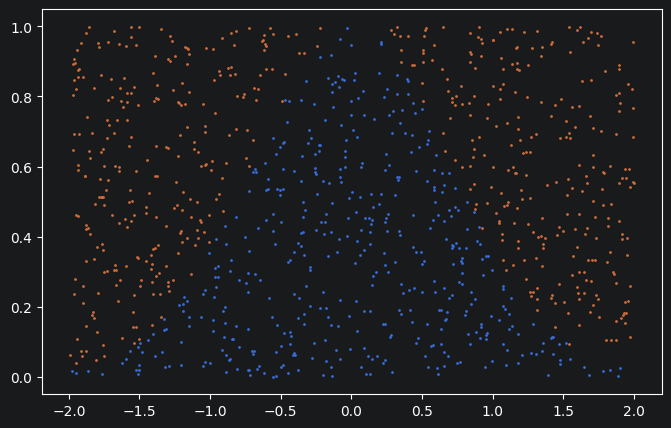

In [157]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 2, 1000)
y = np.exp(-x**2)

plt.figure(figsize=(8, 5))
plt.plot(x, y, label='f(x) = exp(-x**2)')
plt.grid(True)
plt.legend()
plt.show()

n = 10**4

x_pkt = np.random.uniform(-2, 2, size=1000)
y_pkt = np.random.uniform(0, 1, size=1000)
f = np.exp(-x_pkt**2)

under_function = f > y_pkt
area = 4 * np.mean(under_function)

fig = plt.figure(figsize=(8, 5))
plt.scatter(x_pkt[under_function], y_pkt[under_function], s=1)
plt.scatter(x_pkt[~under_function], y_pkt[~under_function], s=1)
plt.show()


